# B1 — Zero-shot NLI

`MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`, no training. Three hypothesis wordings (Arabic / French / English),
every preprocessing of `results.csv` (+ a few PLM-oriented ones). `P(sarcastic)` is thresholded on **val**. Test stays sealed.

In [1]:
import os
import sys

REPO = "Arabic-sarcasm"

if not os.path.exists(f"/content/{REPO}"):
    !git clone https://github.com/cad0m/{REPO}.git /content/{REPO}
else:
    !git -C /content/{REPO} pull

%cd /content/{REPO}

if f"/content/{REPO}" not in sys.path:
    sys.path.insert(0, f"/content/{REPO}")

!pip install -q uv
!uv pip install --system emoji tashaphyne

Cloning into '/content/Arabic-sarcasm'...
remote: Enumerating objects: 80, done.
remote: Counting objects: 100% (80/80), done.
remote: Compressing objects: 100% (51/51), done.
remote: Total 80 (delta 35), reused 61 (delta 21), pack-reused 0 (from 0)
Receiving objects: 100% (80/80), 452.12 KiB | 6.85 MiB/s, done.
Resolving deltas: 100% (35/35), done.
/content/Arabic-sarcasm
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 103.1 MB/s eta 0:00:00
Using Python 3.13.15 environment at: /usr
Resolved 4 packages in 189ms
Prepared 3 packages in 53ms
Installed 3 packages in 2ms
 + emoji==2.16.0
 + pyarabic==0.6.15
 + tashaphyne==0.3.6


In [2]:
# arabert pins an old emoji (1.x, no Arabic names): install it without deps, then force emoji>=2.16.
# If you see a KeyError in emoji.demojize, restart the runtime once and re-run from the top.
%pip install -q --no-deps arabert
%pip install -q -U "emoji>=2.16" pyarabic sentencepiece protobuf

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 179.3/179.3 kB 6.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 343.2/343.2 kB 9.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydf 0.15.0 requires protobuf<7.0.0,>=5.29.1, but you have protobuf 7.36.2 which is incompatible.


In [3]:
import time

import numpy as np
import pandas as pd
import torch
from transformers import pipeline

from src.data import get_data
from src.evaluate import log_result, metrics, plot_results, save_predictions, show
from src.preprocess import build_pipeline
from src.train import best_threshold, set_seed

set_seed(42)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(DEVICE)

/usr/local/lib/python3.13/dist-packages/tashaphyne/stemming.py:106: SyntaxWarning: invalid escape sequence '\w'
  self.token_pat = re.compile(u"[^\w\u064b-\u0652']+", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:274: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN = re.compile(u"([^\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:276: SyntaxWarning: invalid escape sequence '\w'
  TOKEN_PATTERN_SPLIT = re.compile(u"([\w\u0670\u064b-\u0652']+)", re.UNICODE)
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:281: SyntaxWarning: invalid escape sequence '\s'
  ARABIC_STRING = re.compile(u"([^\u0600-\u0652%s%s%s\s\d])" \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1237: SyntaxWarning: invalid escape sequence '\s'
  u"(?<=\s(%s|%s))%s" % (WAW, YEH, FATHA), \
/usr/local/lib/python3.13/dist-packages/pyarabic/araby.py:1450: SyntaxWarning: invalid escape sequence '\s'
  text = re.sub(u"(?<=[

cuda


In [4]:
train, val, test, report = get_data()
y_val = val["sarcasm"].values
print(f"val: {len(val)} | sarcasm rate: {y_val.mean():.3f}")

val: 1255 | sarcasm rate: 0.173


In [5]:
BASE = ["html", "mentions", "hashtags"]
EMOJI = ["emoji"]
NORM = ["diacritics", "kashida", "letters", "elongation"]
LIGHT = ["light_stem"]
URLS = ["urls"]

COMBOS = {
    # same names / definitions as 02_baseline (so rows are comparable in results.csv)
    "base":                      BASE,
    "emoji":                     BASE + EMOJI,
    "norm":                      BASE + NORM,
    "light_stem":                BASE + LIGHT,
    "emoji + norm":              BASE + EMOJI + NORM,
    "emoji + light_stem":        BASE + EMOJI + LIGHT,
    "norm + light_stem":         BASE + NORM + LIGHT,
    "emoji + norm + light_stem": BASE + EMOJI + NORM + LIGHT,
    "urls kept":                 BASE,
    # added for PLMs: URLs -> <URL>, no stemming, AraBERT's own preprocessor
    "urls replaced":             BASE + URLS,
    "emoji + urls replaced":     BASE + URLS + EMOJI,
    "minimal":                   ["html", "urls", "mentions"],   # what 05_finetune uses
    "arabert":                   None,
}

In [6]:
def make_prep(steps):
    if steps is None:
        from arabert.preprocess import ArabertPreprocessor
        return ArabertPreprocessor(model_name="aubmindlab/bert-base-arabertv02-twitter").preprocess
    return build_pipeline(steps)


def prepare(frame, steps):
    prep = make_prep(steps)
    texts = [prep(tweet) for tweet in frame["tweet"]]
    return [t if t.strip() else raw for t, raw in zip(texts, frame["tweet"])]


try:
    make_prep(None)("هذا مثال 😂 @user #وسم_تجريبي http://t.co/x")   # fails here, not mid-run, if arabert is incompatible
except Exception as error:
    print("arabert preprocessing skipped:", error)
    COMBOS.pop("arabert")

print(list(COMBOS))
print("base       :", prepare(val.head(4), COMBOS["base"])[3][:100])
print("urls kept == base (BASE has no urls step), so those two rows are expected to match")

arabert preprocessing skipped: module 'emoji' has no attribute 'UNICODE_EMOJI'
['base', 'emoji', 'norm', 'light_stem', 'emoji + norm', 'emoji + light_stem', 'norm + light_stem', 'emoji + norm + light_stem', 'urls kept', 'urls replaced', 'emoji + urls replaced', 'minimal']
base       : "ريكي مارتن يخطب الرسام السوري جوان يوسفhttps://t.co/vm0NYjJIRF"
urls kept == base (BASE has no urls step), so those two rows are expected to match


In [7]:
def slug(name):
    return name.replace(" + ", "+").replace(" ", "_")

HYPOTHESES = {
    "ar": (["ساخرة", "جادة"],          "هذه التغريدة {}."),
    "fr": (["sarcastique", "sérieux"], "Ce tweet est {}."),
    "en": (["sarcastic", "serious"],   "This tweet is {}."),
}

zs = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=0 if DEVICE == "cuda" else -1,
)

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

...

spm.model: downloading bytes:           |  0.00B            

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

In [8]:
def run(combos, lang):
    labels, template = HYPOTHESES[lang]
    name_model = f"zeroshot_nli_{lang}"
    rows, seen = [], {}

    for name, steps in combos.items():
        texts = prepare(val, steps)
        h = hash(tuple(texts))

        start = time.time()
        if h not in seen:                       # identical texts (base / urls kept) are scored once
            out = zs(texts, candidate_labels=labels, hypothesis_template=template, batch_size=32)
            seen[h] = np.array([dict(zip(o["labels"], o["scores"]))[labels[0]] for o in out])
        proba = seen[h]
        seconds = time.time() - start

        threshold = best_threshold(y_val, proba)
        scores = metrics(y_val, proba, threshold)

        log_result(
            model=name_model,
            preprocessing=name,
            seed=42,
            threshold=threshold,
            train_time=0.0,
            trained_params=0,
            **{f"val_{k}": v for k, v in scores.items()}
        )
        save_predictions(f"{name_model}_{slug(name)}", 42, val["id"], y_val, proba, threshold)

        show(f"{lang} | {name}", scores, threshold, seconds)
        rows.append({"model": name_model, "preprocessing": name, "threshold": threshold, **scores})

    return pd.DataFrame(rows).set_index("preprocessing")

In [9]:
tables = {lang: run(COMBOS, lang) for lang in HYPOTHESES}

ar | base                    f1=0.3923  pr_auc=0.3334  threshold=0.82  8s
ar | emoji                   f1=0.4067  pr_auc=0.3282  threshold=0.81  8s
ar | norm                    f1=0.3905  pr_auc=0.3259  threshold=0.82  6s
ar | light_stem              f1=0.3740  pr_auc=0.3027  threshold=0.85  4s
ar | emoji + norm            f1=0.3932  pr_auc=0.3185  threshold=0.80  5s
ar | emoji + light_stem      f1=0.3810  pr_auc=0.2935  threshold=0.83  4s
ar | norm + light_stem       f1=0.3772  pr_auc=0.2676  threshold=0.85  4s
ar | emoji + norm + light_stem f1=0.3929  pr_auc=0.2625  threshold=0.84  4s
ar | urls kept               f1=0.3923  pr_auc=0.3334  threshold=0.82  0s
ar | urls replaced           f1=0.4031  pr_auc=0.3441  threshold=0.81  4s


[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


ar | emoji + urls replaced   f1=0.4174  pr_auc=0.3386  threshold=0.81  5s
ar | minimal                 f1=0.4023  pr_auc=0.3450  threshold=0.79  4s
fr | base                    f1=0.4073  pr_auc=0.3238  threshold=0.74  4s
fr | emoji                   f1=0.4116  pr_auc=0.3197  threshold=0.74  5s
fr | norm                    f1=0.3823  pr_auc=0.3063  threshold=0.71  5s
fr | light_stem              f1=0.3636  pr_auc=0.2981  threshold=0.90  4s
fr | emoji + norm            f1=0.3866  pr_auc=0.3001  threshold=0.71  5s
fr | emoji + light_stem      f1=0.3510  pr_auc=0.2843  threshold=0.86  5s
fr | norm + light_stem       f1=0.3533  pr_auc=0.2741  threshold=0.85  4s
fr | emoji + norm + light_stem f1=0.3445  pr_auc=0.2616  threshold=0.84  4s
fr | urls kept               f1=0.4073  pr_auc=0.3238  threshold=0.74  0s
fr | urls replaced           f1=0.4179  pr_auc=0.3357  threshold=0.73  4s
fr | emoji + urls replaced   f1=0.4218  pr_auc=0.3349  threshold=0.72  5s
fr | minimal                 f1=0.41

In [10]:
print(f"val F1 (sarcastic) — a random classifier has PR-AUC ≈ {y_val.mean():.3f}")
pd.DataFrame({lang: t["f1"] for lang, t in tables.items()}).round(4)

val F1 (sarcastic) — a random classifier has PR-AUC ≈ 0.173


,ar,fr,en
preprocessing,,,
base,0.3923,0.4073,0.4018
emoji,0.4067,0.4116,0.4141
norm,0.3905,0.3823,0.3891
light_stem,0.3740,0.3636,0.3647
emoji + norm,0.3932,0.3866,0.3901
emoji + light_stem,0.3810,0.3510,0.3568
norm + light_stem,0.3772,0.3533,0.3528
emoji + norm + light_stem,0.3929,0.3445,0.3490
urls kept,0.3923,0.4073,0.4018


In [11]:
pd.DataFrame({lang: t["pr_auc"] for lang, t in tables.items()}).round(4)

,ar,fr,en
preprocessing,,,
base,0.3334,0.3238,0.3247
emoji,0.3282,0.3197,0.3213
norm,0.3259,0.3063,0.3107
light_stem,0.3027,0.2981,0.2942
emoji + norm,0.3185,0.3001,0.3065
emoji + light_stem,0.2935,0.2843,0.2783
norm + light_stem,0.2676,0.2741,0.2753
emoji + norm + light_stem,0.2625,0.2616,0.2645
urls kept,0.3334,0.3238,0.3247


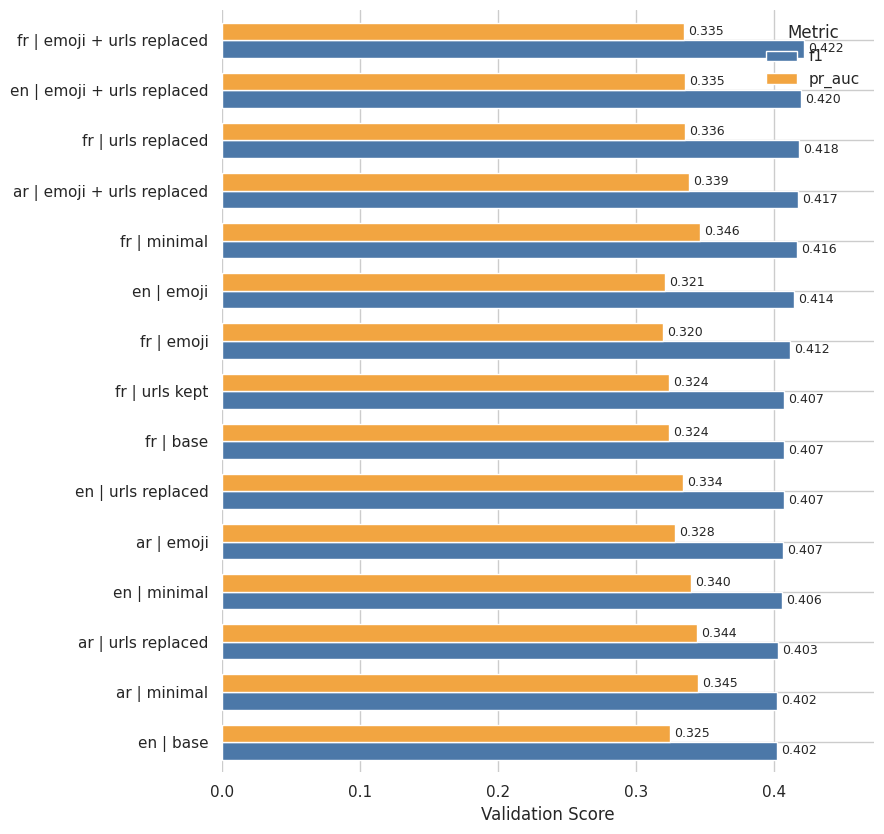

In [12]:
summary = pd.concat([t.assign(name=lang + " | " + t.index) for lang, t in tables.items()]).set_index("name")
plot_results(summary.nlargest(15, "f1"))